## Analyzing big NSGAII run

In [48]:
import os
import re
import glob
import json
import numpy as np
import pandas as pd
from pymoo.indicators.hv import HV
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Rectangle
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, BoundaryNorm
from matplotlib.lines import Line2D
from scipy.stats import spearmanr

In [49]:
output_folder = "/storage/users/anne_sophie/nsgaii_fI_fSA_h63"
# all slurm job files need to be added here
log_files = ["log_nsgaii_fI_fSA_3022465.out", "log_nsgaii_fI_fSA_3023681.out"]
comparison_generation = None # none means last one

In [50]:
per_seed = pd.read_csv(os.path.join(output_folder, "per_seed.csv")) # objective values are in there
settings_files = sorted(glob.glob(os.path.join(output_folder, "run_settings*.json")),key=lambda path: int((re.findall(r"from_generation_(\d+)", path) or ["0"])[0]))
run_settings_per_start = {}
for path in settings_files:
    with open(path) as file:
        run_settings_per_start[int((re.findall(r"from_generation_(\d+)", path) or ["0"])[0])] = json.load(file)
run_settings = run_settings_per_start[min(run_settings_per_start)] # first run
objectives = run_settings["objectives"]
continued_from = sorted(start for start in run_settings_per_start if start > 0)   # [10] im ersten Versuch
population_files = sorted(glob.glob(os.path.join(output_folder, "population_generation_*.csv")),
                          key=lambda path: int(re.findall(r"(\d+)\.csv$", path)[0]))
# front.csv file is only written in the end of nsgaii -> while it is still running, none or takes the one from the last run (z.B. 0-10)
front_file = os.path.join(output_folder, "front.csv") 
front = pd.read_csv(front_file) if os.path.exists(front_file) else None
generations = sorted(per_seed["generation"].unique())
print("All generations:", generations)
if comparison_generation is None: # if none -> take last generation
    comparison_generation = continued_from[-1] if continued_from else generations[-1]
print("Generation for comparison:", comparison_generation )
job_of_generation = {int(generation): int(1 + sum(generation > start for start in continued_from)) for generation in generations}
print("Which generation was in which job?", job_of_generation)

All generations: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11)]
Generation for comparison: 10
Which generation was in which job? {0: 1, 1: 1, 2: 1, 3: 1, 4: 1, 5: 1, 6: 1, 7: 1, 8: 1, 9: 1, 10: 1, 11: 2}


Print for every generation time, duration and short overview of performance
 

In [51]:
def parse_log(path, job):
    rows, last_pymoo, last_time, simulations = [], None, 0.0, 0
    for line in open(path, errors="replace"):
        pymoo_match = re.match(r"^\s+(\d+) \|\s+(\d+) \|\s+(\d+) \|\s+(\S+) \|\s+(\S+)", line)
        if pymoo_match:
            last_pymoo = pymoo_match.groups()
        if "Time for advancing simulation" in line:
            simulations += 1
        # new generation finished
        saved_match = re.search(r"Saved population of generation (\d+), time ([\d.]+) s", line) 
        if saved_match:
            generation, time_point = int(saved_match.group(1)), float(saved_match.group(2))
            rows.append({"generation": generation, "job": job, "duration_h": (time_point - last_time) / 3600,
                         "simulations": simulations, "n_nds": int(last_pymoo[2]) if last_pymoo else np.nan,
                         "pymoo_eps": last_pymoo[3] if last_pymoo else "-", "indicator": last_pymoo[4] if last_pymoo else "-"})
            last_time, simulations = time_point, 0
    # save all information from the log
    text = open(path, errors="replace").read()
    summary = {"job": job, "log": os.path.basename(path), "cpus": (re.findall(r"CPUs: (\d+)", text) or ["?"])[0],
               "simulations": text.count("Time for advancing simulation"), "failed": text.count("[FAILED]"),
               "process_failed": text.count("[PROCESS FAILED]"),
               "advance_mean_s": np.mean([float(t) for t in re.findall(r"Time for advancing simulation: ([\d.]+)", text)] or [np.nan]),
               "finished": "Pareto front:" in text}
    return rows, summary
 
 
log_rows, log_summaries = [], []
for job, path in enumerate([path for path in log_files if os.path.exists(path)], start=1):
    rows, summary = parse_log(path, job)
    log_rows += rows
    log_summaries.append(summary)
generation_log = pd.DataFrame(log_rows)
print(generation_log)

    generation  job  duration_h  simulations  n_nds     pymoo_eps indicator
0            0    1    6.013056          576      3             -         -
1            1    1    6.005000          576      4  0.1084473136     ideal
2            2    1    6.003056          576      9  0.2160827651     ideal
3            3    1    6.005278          576     11  0.1067952147     ideal
4            4    1    5.995278          576     12  0.0355531899     ideal
5            5    1    5.984722          576     18  0.0319017416     ideal
6            6    1    5.991389          576     19  0.0172626861     ideal
7            7    1    5.987222          576     24  0.0611777122     ideal
8            8    1    5.993333          576     18  0.0025246854     nadir
9            9    1    6.007222          576     18  0.0060617079     ideal
10          10    1    5.979722          576     24  0.0045861835     ideal
11          10    2    0.000000            0     24             -         -
12          

Check if 
- there were any problems (mismatch in amounts, etc)
- any failed processes
- all parameter were chosen as thought

In [52]:
print("=" * 90)
print(f"Lauf: {output_folder}")
print("=" * 90)
print(f"Ziele: {objectives}")
print(f"Constraints: {run_settings.get('constraints') or 'keine'}")
print(f"Populationsgröße: {run_settings.get('population_size')}")
print(f"Partikel (Seeds): {len(run_settings.get('seed_indices', []))} -> {run_settings.get('seed_indices')}")
print(f"KAPPA_FACTOR: {run_settings.get('kappa_factor')}, Partikeldatei {run_settings.get('particle_file')}")
print(f"Simulation / Auswertung bis Tag: {run_settings.get('simulation_days')} / {run_settings.get('evaluation_end_day')}")
print(f"Wechseltage: {run_settings.get('earliest_change_day')}-{run_settings.get('latest_change_day')}, "
      f"Mindestabstand {run_settings.get('minimum_period_days')} Tage")
print(f"Kontaktdateien: {run_settings.get('contact_files')}")
print(f"Generation 0 aus: {run_settings.get('generation_0_folder', 'im Lauf simuliert')}")
print(f"Starts: Generation {sorted(run_settings_per_start)} "
      f"({'fortgesetzt nach Generation ' + ', '.join(map(str, continued_from)) if continued_from else 'ein Job'})")

# check if there were any differences between the two jobs
changed = {key for settings in run_settings_per_start.values() for key in settings
           if key not in ("new_generations", "pymoo_seed")
           and len({json.dumps(other.get(key), sort_keys=True) for other in run_settings_per_start.values()}) > 1}
print(f"Geänderte Einstellungen zwischen den Starts: {sorted(changed) if changed else 'keine'}")
print(f"Generationen: 0 bis {max(generations)} ({len(generations)} insgesamt), gespeicherte Populationen: {len(population_files)}")
rows_per_generation = per_seed.groupby("generation").size()
print(f"Zeilen in per_seed: {len(per_seed)}; pro Generation {rows_per_generation.to_dict()}")
expected_rows = run_settings["population_size"] * len(run_settings.get("seed_indices", []))
unusual = rows_per_generation[(rows_per_generation != expected_rows) & (rows_per_generation.index > 0)]
print(f"Generationen mit ungewöhnlich vielen Zeilen (erwartet {expected_rows}): {unusual.to_dict() if len(unusual) else 'keine'}"
      " (Generation 0 darf doppelt sein)")
print(f"Bewertete Strategien: {per_seed.groupby(['generation', 'strategy']).ngroups}")
print(f"Fehlende Zielwerte: {per_seed[objectives].isna().any(axis=1).sum()}")
if front is not None:
    print(f"front.csv: {len(front)} Strategien, " +
          ", ".join(f"{name} {front[name].min():.4g}-{front[name].max():.4g}" for name in objectives))
else:
    print("front.csv: fehlt (Job läuft noch oder endete am Zeitlimit; für die Auswertung nicht nötig)")
 
if log_summaries:
    print("\nJobs laut Log:")
    print(pd.DataFrame(log_summaries).round(0).to_string(index=False))
    if len(generation_log):
        simulated_generations = generation_log[generation_log["simulations"] > 0]
        print(f"Dauer pro simulierter Generation: Mittel {simulated_generations['duration_h'].mean():.1f} h, "
              f"gesamt {generation_log['duration_h'].sum():.1f} h")
print("=" * 90)

Lauf: /storage/users/anne_sophie/nsgaii_fI_fSA_h63
Ziele: ['f_I', 'f_S_A']
Constraints: keine
Populationsgröße: 48
Partikel (Seeds): 12 -> [19, 23, 28, 35, 41, 44, 50, 51, 52, 53, 58, 71]
KAPPA_FACTOR: 2.2, Partikeldatei pop8_sel_particles.csv
Simulation / Auswertung bis Tag: 63 / 63
Wechseltage: 19-49, Mindestabstand 7 Tage
Kontaktdateien: {'Home': ['baseline_home.txt', 1.0], 'School': ['baseline_school_pf_eig.txt', 1.0], 'Work': ['baseline_work.txt', 1.0], 'SocialEvent': ['baseline_other.txt', 0.6], 'BasicsShop': ['baseline_other.txt', 0.4]}
Generation 0 aus: /storage/users/anne_sophie/screening_kappa_2.2_12_seeds_h77_d19_notest
Starts: Generation [0, 10] (fortgesetzt nach Generation 10)
Geänderte Einstellungen zwischen den Starts: keine
Generationen: 0 bis 11 (12 insgesamt), gespeicherte Populationen: 12
Zeilen in per_seed: 7488; pro Generation {0: 1152, 1: 576, 2: 576, 3: 576, 4: 576, 5: 576, 6: 576, 7: 576, 8: 576, 9: 576, 10: 576, 11: 576}
Generationen mit ungewöhnlich vielen Zei

Help functions:

In [53]:
def non_dominated_mask(points):
    return np.array([not ((points <= point).all(axis=1) & (points < point).any(axis=1)).any() for point in points])

def non_dominated(points):
    return points[non_dominated_mask(points)]

def additive_epsilon(approximation, reference):
    # epsilon indiciator (additive and binär)
    differences = approximation[:, np.newaxis, :] - reference[np.newaxis, :, :]
    return differences.max(axis=2).min(axis=0).max()

def paired_noise(frame, objective):
    # strategy x particles
    table = frame.pivot(index="strategy_id", columns="seed_index", values=objective).dropna().to_numpy()
    first, second = np.triu_indices(len(table), k=1)
    differences = table[first] - table[second]
    standard_errors = differences.std(axis=1, ddof=1) / np.sqrt(differences.shape[1])
    return {"median": np.median(standard_errors), "mean": standard_errors.mean(),
            "pooled": np.sqrt((standard_errors ** 2).mean())}, len(first)

Check convergence: 
1) Take mean of all 12 ("Partikel") particles for every strategy
2) Standardise (because the two objectives are too far from each other)
    $$f_{standardised} = (f - ideal_{point}) / (nadir_{point} - ideal_{point})$$
    ideal_point: best value of every objective
    nadir_point: worst value of every objective on the final front
    // for every generation the same (!)
3) Take all non-dominated strategies of every generation (we will call it archive)
4) Calculate Hypervolume 
5) Calculate epsilon indicator
6) Check noise: how small can a improvement be s.t. we can still prove it with 12 particles? (for all pairs of strategies calculate difference between particles and then take standard error)

In [54]:
# 1
means = per_seed.groupby(["generation", "strategy"])[objectives].mean().reset_index()
#2
raw_points = means[objectives].to_numpy()
on_final_front = non_dominated_mask(raw_points)
ideal, nadir = raw_points[on_final_front].min(axis=0), raw_points[on_final_front].max(axis=0)
normalized = (raw_points - ideal) / (nadir - ideal)
# 3 
archives = {generation: non_dominated(normalized[means["generation"].to_numpy() <= generation]) for generation in generations}
final_front_normalized = archives[generations[-1]]
# 4 
population_size = run_settings["population_size"]
reference_value = 1 + 1 / (population_size - 1)   
indicator = HV(ref_point=np.full(len(objectives), reference_value))
print(f"Idealpunkt {dict(zip(objectives, ideal.round(4).tolist()))}, Nadirpunkt {dict(zip(objectives, nadir.round(4).tolist()))}, "
      f"Referenzpunkt {reference_value:.4f} (normiert)")
# 4 and 5
rows = []
for generation in generations:
    rows.append({"generation": generation,
                 "front_points": len(archives[generation]),                     
                 "hypervolume": indicator(archives[generation]),   
                 "eps_to_previous": additive_epsilon(archives[generation - 1], archives[generation]) if generation > 0 else np.nan,
                 "eps_to_final": additive_epsilon(archives[generation], final_front_normalized)})
progress = pd.DataFrame(rows)
progress["hv_change_percent"] = 100 * progress["hypervolume"].pct_change() 
progress.insert(1, "job", progress["generation"].map(job_of_generation))
print(progress.round(4).to_string(index=False))
if continued_from:
    print(f"Fortgesetzt nach Generation {continued_from}: ab dort neuer Job mit neuem Zufallsstrom (pymoo-Seed + Generation)")

Idealpunkt {'f_I': 18676.3333, 'f_S_A': 0.0588}, Nadirpunkt {'f_I': 34504.1667, 'f_S_A': 0.5142}, Referenzpunkt 1.0213 (normiert)
 generation  job  front_points  hypervolume  eps_to_previous  eps_to_final  hv_change_percent
          0    1             3       0.5367              NaN        0.2905                NaN
          1    1             4       0.6401           0.1126        0.2048            19.2572
          2    1             9       0.6915           0.1258        0.2001             8.0335
          3    1            11       0.7597           0.1260        0.1531             9.8660
          4    1            12       0.7794           0.0300        0.1531             2.5926
          5    1            18       0.8116           0.0740        0.1029             4.1298
          6    1            19       0.8459           0.0864        0.0771             4.2273
          7    1            24       0.8638           0.0604        0.0709             2.1141
          8    1        

Attention: the first job was done with pymoo seed (! not our particle seed) = 1 for job 1 and then took from the random stream. We didn't save that and the second job was then started with a random stream starting at 11

In [55]:
# 6
noise_runs = per_seed.drop_duplicates(["generation", "strategy", "seed_index"])
noise_runs = noise_runs.assign(strategy_id=noise_runs["generation"].astype(str) + "_" + noise_runs["strategy"].astype(str))
front_ids = set((means.loc[on_final_front, "generation"].astype(str) + "_" + means.loc[on_final_front, "strategy"].astype(str)))
print("Rauschen eines Strategievergleichs, normiert auf die Spannweite der Endfront (pooled = Wurzel aus dem Mittel der SE^2):")
for label, frame in [("alle Strategien", noise_runs), ("Endfront", noise_runs[noise_runs["strategy_id"].isin(front_ids)])]:
    for objective, span in zip(objectives, nadir - ideal):
        noise, number_of_pairs = paired_noise(frame, objective)
        print(f"   {label:>16}, {objective}: " + ", ".join(f"{name} {value / span:.4f}" for name, value in noise.items())
              + f"  (absolut pooled {noise['pooled']:.4g}, {number_of_pairs} Paare)")

Rauschen eines Strategievergleichs, normiert auf die Spannweite der Endfront (pooled = Wurzel aus dem Mittel der SE^2):


    alle Strategien, f_I: median 0.0285, mean 0.0340, pooled 0.0411  (absolut pooled 651.2, 165600 Paare)
    alle Strategien, f_S_A: median 0.0001, mean 0.0001, pooled 0.0001  (absolut pooled 6.308e-05, 165600 Paare)
           Endfront, f_I: median 0.0321, mean 0.0434, pooled 0.0568  (absolut pooled 898.9, 325 Paare)
           Endfront, f_S_A: median 0.0001, mean 0.0001, pooled 0.0001  (absolut pooled 5.239e-05, 325 Paare)


For the first run ever: was it good to do a second job? Did it help?

In [56]:
if comparison_generation not in archives:
    raise ValueError(f"Generation {comparison_generation} nicht vorhanden, vorhanden: {generations}")
before = archives[comparison_generation]          
after = archives[generations[-1]]  # Endfront (normiert)
hypervolume_before, hypervolume_after = indicator(before), indicator(after)
front_noise, _ = paired_noise(noise_runs[noise_runs["strategy_id"].isin(front_ids)], objectives[0])
health_span = (nadir - ideal)[0]                  
print(f"Vergleich Generation {comparison_generation} -> {generations[-1]} "
      f"({generations[-1] - comparison_generation} Generationen später):")
print(f"   Hypervolumen: {hypervolume_before:.4f} -> {hypervolume_after:.4f} "
      f"(+{100 * (hypervolume_after / hypervolume_before - 1):.2f} %)")
print(f"   eps: Front {comparison_generation} muss um {additive_epsilon(before, after):.4f} verbessert werden, um die Endfront "
      f"zu erreichen (= {additive_epsilon(before, after) * health_span:.0f} in {objectives[0]}); "
      f"\nRauschen Endfront pooled {front_noise['pooled'] / health_span:.4f}")
print(f"   umgekehrt: Endfront gegen Front {comparison_generation}: {additive_epsilon(after, before):.4f} "
      "(0 = Endfront ist überall mindestens so gut)")
final_members = means.loc[on_final_front, ["generation", "strategy"] + objectives].copy()
final_members["gain_vs_comparison"] = [max(0.0, (before - point).max(axis=1).min()) for point in normalized[on_final_front]]
final_members["found"] = np.where(final_members["generation"] > comparison_generation,
                                  f"after {comparison_generation}", f"up to {comparison_generation}")
final_members = final_members.sort_values(objectives[1])
print(f"Strategien der Endfront: {len(final_members)}, davon gefunden {final_members['found'].value_counts().to_dict()}")
print(f"gefunden in Generation: {final_members['generation'].value_counts().sort_index().to_dict()}")
# sorted after f_S_A
print(final_members.round(4).to_string(index=False))
 

Vergleich Generation 10 -> 11 (1 Generationen später):
   Hypervolumen: 0.9205 -> 0.9276 (+0.77 %)
   eps: Front 10 muss um 0.0374 verbessert werden, um die Endfront zu erreichen (= 593 in f_I); 
Rauschen Endfront pooled 0.0568
   umgekehrt: Endfront gegen Front 10: 0.0000 (0 = Endfront ist überall mindestens so gut)
Strategien der Endfront: 26, davon gefunden {'up to 10': 14, 'after 10': 12}
gefunden in Generation: {7: 1, 8: 3, 9: 3, 10: 7, 11: 12}
 generation  strategy        f_I  f_S_A  gain_vs_comparison    found
         11         1 34504.1667 0.0588              0.0017 after 10
          8        12 33048.2500 0.0596              0.0000 up to 10
         11        24 32829.5000 0.0607              0.0128 after 10
         11         6 32217.0000 0.0655              0.0120 after 10
         11         7 27474.2500 0.0669              0.0164 after 10
         11        14 26805.3333 0.0698              0.0220 after 10
         10        16 25297.0000 0.0959              0.0000 up 

Plot: Convergence over generations

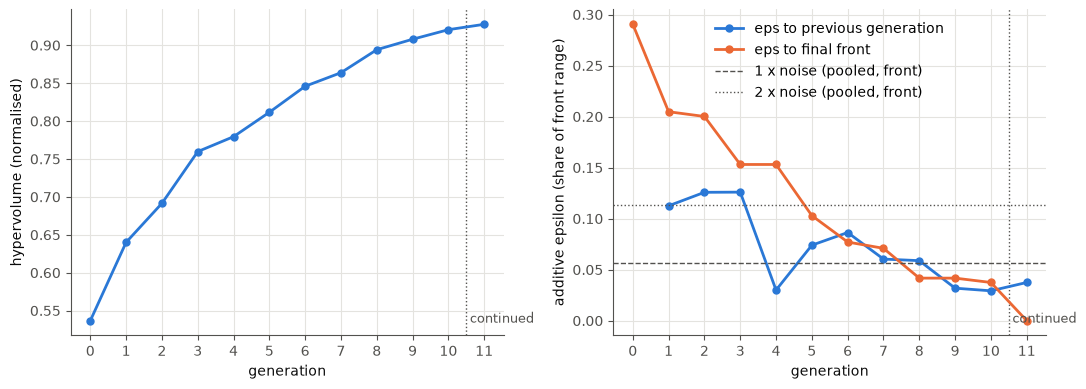

In [57]:
figure, (left, right) = plt.subplots(1, 2, figsize=(11, 4))
for axis in (left, right):
    axis.grid(color="#e4e3df", linewidth=0.8)
    axis.set_axisbelow(True)
    for spine in ("top", "right"):
        axis.spines[spine].set_visible(False)
    for start in continued_from: # mark where the second job started                 
        axis.axvline(start + 0.5, color="#52514e", linewidth=1, linestyle=":")
        axis.text(start + 0.6, 0.03, "continued", transform=axis.get_xaxis_transform(), color="#52514e",
                  fontsize=9, va="bottom")
left.plot(progress["generation"], progress["hypervolume"], color="#2a78d6", linewidth=2, marker="o", markersize=5)
left.set_ylabel("hypervolume (normalised)")
right.plot(progress["generation"], progress["eps_to_previous"], color="#2a78d6", linewidth=2, marker="o", markersize=5,
           label="eps to previous generation") # what every generation added
right.plot(progress["generation"], progress["eps_to_final"], color="#eb6834", linewidth=2, marker="o", markersize=5,
           label="eps to final front") # how far generation was away from final front
for factor, style in [(1, "--"), (2, ":")]:    # noise: if smaller, will probably not help anymore  
    right.axhline(factor * front_noise["pooled"] / health_span, color="#52514e", linewidth=1, linestyle=style,
                  label=f"{factor} x noise (pooled, front)")
right.set_ylabel("additive epsilon (share of front range)")
right.legend(frameon=False)
for axis in (left, right):
    axis.set_xlabel("generation")
    axis.set_xticks(generations)
figure.tight_layout()
plt.show()

Noise between neighbors (bc noise_threshold is too high after looking at one of the plots coming after bc taking too many infections)

In [58]:
front_order = means.loc[on_final_front].sort_values(objectives[1])
neighbor_ids = (front_order["generation"].astype(str) + "_" + front_order["strategy"].astype(str)).tolist()
neighbor_table = (noise_runs[noise_runs["strategy_id"].isin(neighbor_ids)]
                  .pivot(index="strategy_id", columns="seed_index", values=objectives[0]).loc[neighbor_ids].to_numpy())
neighbor_differences = np.diff(neighbor_table, axis=0)                 
neighbor_standard_errors = neighbor_differences.std(axis=1, ddof=1) / np.sqrt(neighbor_differences.shape[1])
front_noise = {"median": np.median(neighbor_standard_errors), "mean": neighbor_standard_errors.mean(),
               "pooled": np.sqrt((neighbor_standard_errors ** 2).mean())}
print("Rauschen zwischen benachbarten Frontstrategien, normiert: "
      + ", ".join(f"{name} {value / (nadir - ideal)[0]:.4f}" for name, value in front_noise.items())
      + f"  (absolut pooled {front_noise['pooled']:.0f}, {len(neighbor_standard_errors)} Nachbarpaare)")

Rauschen zwischen benachbarten Frontstrategien, normiert: median 0.0051, mean 0.0081, pooled 0.0132  (absolut pooled 209, 25 Nachbarpaare)


Heatmap: every generation against each other (epsilon indicator)

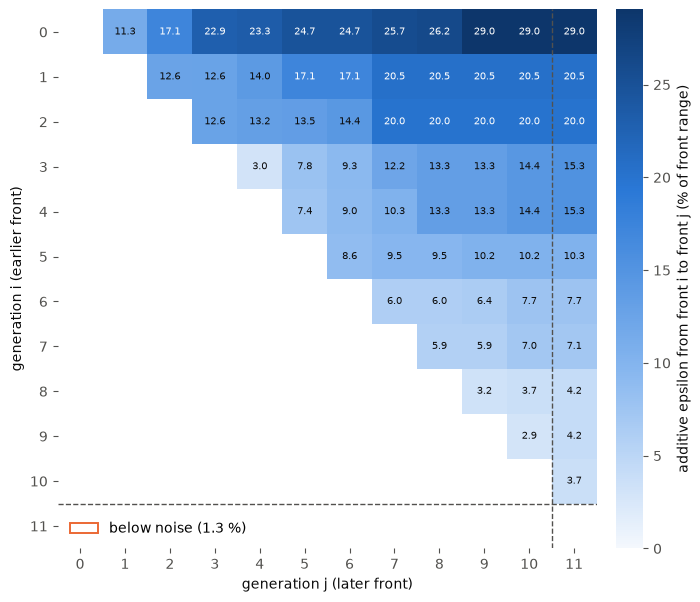

In [59]:
number_of_generations = len(generations)
epsilon_matrix = np.full((number_of_generations, number_of_generations), np.nan)
for row, generation_i in enumerate(generations):
    for column, generation_j in enumerate(generations):
        if generation_j > generation_i:
            epsilon_matrix[row, column] = additive_epsilon(archives[generation_i], archives[generation_j])
noise_threshold = front_noise["pooled"] / health_span        # 1x noise of the final front
 
heatmap_ramp = LinearSegmentedColormap.from_list("epsilon", ["#f4f8fd", "#86b6ef", "#2a78d6", "#0d366b"])
figure, axis = plt.subplots(figsize=(8.5, 7))
image = axis.imshow(100 * epsilon_matrix, cmap=heatmap_ramp, vmin=0, origin="upper")
maximum = np.nanmax(epsilon_matrix)
for row in range(number_of_generations):
    for column in range(number_of_generations):
        value = epsilon_matrix[row, column]
        if np.isnan(value):
            continue
        text_color = "white" if value > 0.55 * maximum else "#0b0b0b"    
        if number_of_generations <= 20:        
            axis.text(column, row, f"{100 * value:.1f}", ha="center", va="center", fontsize=7, color=text_color)
        if value < noise_threshold:                       
            axis.add_patch(Rectangle((column - 0.5, row - 0.5), 1, 1, fill=False, edgecolor="#eb6834", linewidth=1.4))
for start in continued_from:
    position = generations.index(start) + 0.5
    axis.axhline(position, color="#52514e", linewidth=1, linestyle="--")
    axis.axvline(position, color="#52514e", linewidth=1, linestyle="--")
axis.set_xticks(range(number_of_generations))
axis.set_xticklabels(generations)
axis.set_yticks(range(number_of_generations))
axis.set_yticklabels(generations)
axis.set_xlabel("generation j (later front)")
axis.set_ylabel("generation i (earlier front)")
for spine in axis.spines.values():
    spine.set_visible(False)
colorbar = figure.colorbar(image, ax=axis, fraction=0.046, pad=0.03)
colorbar.set_label("additive epsilon from front i to front j (% of front range)")
colorbar.outline.set_visible(False)
axis.legend(handles=[Rectangle((0, 0), 1, 1, fill=False, edgecolor="#eb6834", linewidth=1.4,
                               label=f"below noise ({100 * noise_threshold:.1f} %)")],
            frameon=False, loc="lower left")
plt.show()

Plots of the front

In [60]:
settled = [int(generation) for row, generation in enumerate(generations[:-1])
           if np.nanmax(epsilon_matrix[row, row + 1:]) < noise_threshold]
if settled:
    print(f"Ab Generation {settled[0]} bringt keine spätere Generation mehr als das Rauschen "
          f"({100 * noise_threshold:.1f} % der Spannweite). Generationen mit dieser Eigenschaft: {settled}")
else:
    print(f"Keine Generation, nach der alle späteren weniger als das Rauschen ({100 * noise_threshold:.1f} %) bringen: "
          "die Front hat sich bis zum Ende nachweisbar verbessert.")

Keine Generation, nach der alle späteren weniger als das Rauschen (1.3 %) bringen: die Front hat sich bis zum Ende nachweisbar verbessert.


Alle Mean of Strategys, all non-dominated and final front

In [61]:
x_objective, y_objective = objectives[1], objectives[0]   
axis_labels = {"f_I": "new infections f_I", "f_S_A": "lost school and event attendance f_S_A",
               "f_W": "lost working attendance f_W", "f_ED": "expected deaths f_ED"}
highlight_particle = None      

generation_ramp = LinearSegmentedColormap.from_list("generations", ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
final_color, ink, muted, grid_color = "#eb6834", "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({"font.size": 10, "axes.edgecolor": muted, "axes.labelcolor": ink, "xtick.color": muted,
                     "ytick.color": muted, "axes.spines.top": False, "axes.spines.right": False})
 
runs = per_seed.drop_duplicates(["generation", "strategy", "seed_index"])
strategy_means = runs.groupby(["generation", "strategy"])[objectives].mean().reset_index()
generations = sorted(strategy_means["generation"].unique())
norm = BoundaryNorm(np.arange(generations[0] - 0.5, generations[-1] + 1.5), generation_ramp.N)
 

def front_of(frame):
    points = frame[objectives].to_numpy()
    keep = [not ((points <= point).all(axis=1) & (points < point).any(axis=1)).any() for point in points]
    return frame[np.array(keep)].sort_values(x_objective)
 
 
final_front = front_of(strategy_means)

576 Strategien aus 12 Generationen, Endfront: 26 Strategien


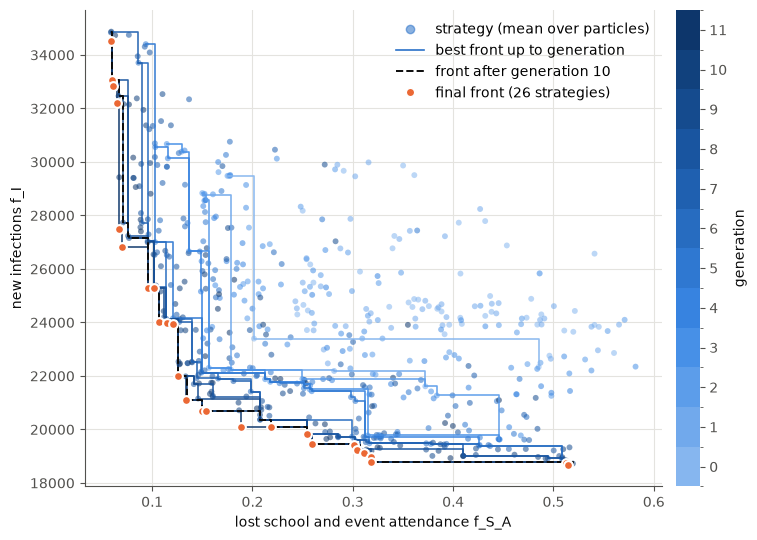

In [62]:
figure, axis = plt.subplots(figsize=(8, 5.5))
axis.grid(color=grid_color, linewidth=0.8)
axis.set_axisbelow(True)
axis.scatter(strategy_means[x_objective], strategy_means[y_objective], c=strategy_means["generation"], cmap=generation_ramp,
             norm=norm, s=18, alpha=0.55, linewidths=0)
for generation in generations:                    # beste Front bis zu jeder Generation
    front = front_of(strategy_means[strategy_means["generation"] <= generation])
    axis.step(front[x_objective], front[y_objective], where="post", color=generation_ramp(norm(generation)),
              linewidth=1.2, alpha=0.9)
comparison_front = front_of(strategy_means[strategy_means["generation"] <= comparison_generation])
axis.step(comparison_front[x_objective], comparison_front[y_objective], where="post", color=ink, linewidth=1.4,
          linestyle="--", zorder=4)
axis.scatter(final_front[x_objective], final_front[y_objective], s=40, color=final_color, edgecolors="white",
             linewidths=1.5, zorder=5)
colorbar = figure.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=generation_ramp), ax=axis, ticks=generations, pad=0.02)
colorbar.set_label("generation", color=ink)
colorbar.outline.set_visible(False)
axis.legend(handles=[Line2D([], [], marker="o", linestyle="", color=generation_ramp(0.5), alpha=0.55, label="strategy (mean over particles)"),
                     Line2D([], [], color=generation_ramp(0.5), linewidth=1.2, label="best front up to generation"),
                     Line2D([], [], color=ink, linewidth=1.4, linestyle="--", label=f"front after generation {comparison_generation}"),
                     Line2D([], [], color=final_color, marker="o", markeredgecolor="white", linestyle="",
                            label=f"final front ({len(final_front)} strategies)")],
            frameon=False, loc="upper right")
axis.set_xlabel(axis_labels.get(x_objective, x_objective))
axis.set_ylabel(axis_labels.get(y_objective, y_objective))
figure.tight_layout()
print(f"{len(strategy_means)} Strategien aus {len(generations)} Generationen, Endfront: {len(final_front)} Strategien")

Plot of every strategy on its different particles

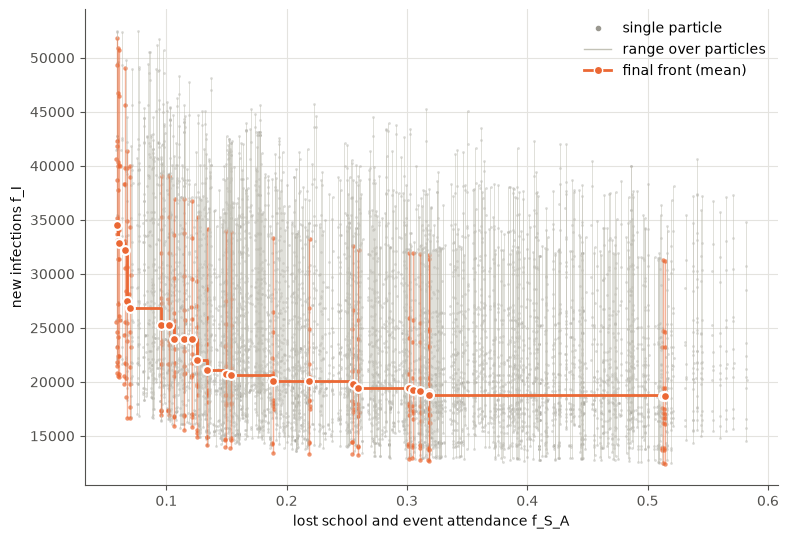

Spanne von f_I über die Partikel relativ zum Mittel: Median 91%, auf der Endfront 95%


In [63]:
particle_values = runs.merge(strategy_means, on=["generation", "strategy"], suffixes=("", "_mean"))
on_final = particle_values.set_index(["generation", "strategy"]).index.isin(final_front.set_index(["generation", "strategy"]).index)

spans = particle_values.groupby(["generation", "strategy"]).agg(x=(f"{x_objective}_mean", "first"),
                                                                 low=(y_objective, "min"), high=(y_objective, "max"))
front_index = final_front.set_index(["generation", "strategy"]).index
 
figure, axis = plt.subplots(figsize=(8, 5.5))
axis.grid(color=grid_color, linewidth=0.8)
axis.set_axisbelow(True)
other = ~spans.index.isin(front_index)
axis.vlines(spans.loc[other, "x"], spans.loc[other, "low"], spans.loc[other, "high"], color="#c3c2b7", linewidth=0.6, alpha=0.6)
axis.scatter(particle_values.loc[~on_final, x_objective], particle_values.loc[~on_final, y_objective], s=4, color="#9a9890",
             alpha=0.35, linewidths=0)
axis.vlines(spans.loc[~other, "x"], spans.loc[~other, "low"], spans.loc[~other, "high"], color=final_color, linewidth=1, alpha=0.5)
axis.scatter(particle_values.loc[on_final, x_objective], particle_values.loc[on_final, y_objective], s=10, color=final_color,
             alpha=0.7, linewidths=0)
axis.step(final_front[x_objective], final_front[y_objective], where="post", color=final_color, linewidth=2)
axis.scatter(final_front[x_objective], final_front[y_objective], s=40, color=final_color, edgecolors="white",
             linewidths=1.5, zorder=5)
handles = [Line2D([], [], marker="o", linestyle="", color="#9a9890", markersize=3, label="single particle"),
           Line2D([], [], color="#c3c2b7", linewidth=1, label="range over particles"),
           Line2D([], [], color=final_color, marker="o", markeredgecolor="white", linewidth=2, label="final front (mean)")]
if highlight_particle is not None:
    chosen = particle_values[particle_values["seed_index"] == highlight_particle]
    axis.scatter(chosen[x_objective], chosen[y_objective], s=12, color="#2a78d6", linewidths=0, zorder=4)
    handles.append(Line2D([], [], marker="o", linestyle="", color="#2a78d6", markersize=4, label=f"particle {highlight_particle}"))
axis.legend(handles=handles, frameon=False, loc="upper right")
axis.set_xlabel(axis_labels.get(x_objective, x_objective))
axis.set_ylabel(axis_labels.get(y_objective, y_objective))
figure.tight_layout()
plt.show()


spread = (spans["high"] - spans["low"]) / particle_values.groupby(["generation", "strategy"])[f"{y_objective}_mean"].first()
print(f"Spanne von {y_objective} über die Partikel relativ zum Mittel: Median {spread.median():.0%}, "
      f"auf der Endfront {spread[spans.index.isin(front_index)].median():.0%}")
 

Same but /mean

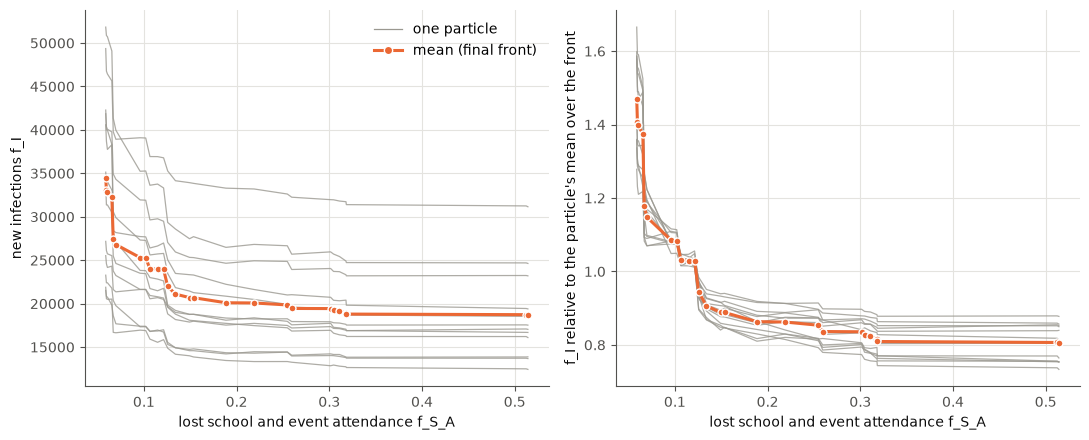

In [64]:
front_runs = runs.merge(final_front[["generation", "strategy", x_objective]].rename(columns={x_objective: "front_x"}),
                        on=["generation", "strategy"])
table = front_runs.pivot_table(index="front_x", columns="seed_index", values=y_objective).sort_index()   
relative = table / table.mean(axis=0)            
mean_line = table.mean(axis=1)
 
figure, (left, right) = plt.subplots(1, 2, figsize=(11, 4.5), sharex=True)
for axis in (left, right):
    axis.grid(color=grid_color, linewidth=0.8)
    axis.set_axisbelow(True)
for particle in table.columns:
    color, width, z = ("#2a78d6", 1.6, 4) if particle == highlight_particle else ("#9a9890", 0.9, 2)
    left.plot(table.index, table[particle], color=color, linewidth=width, alpha=0.8, zorder=z)
    right.plot(relative.index, relative[particle], color=color, linewidth=width, alpha=0.8, zorder=z)
left.plot(mean_line.index, mean_line, color=final_color, linewidth=2.2, marker="o", markersize=5,
          markeredgecolor="white", zorder=5)
right.plot(relative.index, relative.mean(axis=1), color=final_color, linewidth=2.2, marker="o", markersize=5,
           markeredgecolor="white", zorder=5)
left.set_ylabel(axis_labels.get(y_objective, y_objective))
right.set_ylabel(f"{y_objective} relative to the particle's mean over the front")
for axis in (left, right):
    axis.set_xlabel(axis_labels.get(x_objective, x_objective))
handles = [Line2D([], [], color="#9a9890", linewidth=0.9, label="one particle"),
           Line2D([], [], color=final_color, linewidth=2.2, marker="o", markeredgecolor="white", label="mean (final front)")]
if highlight_particle is not None:
    handles.insert(1, Line2D([], [], color="#2a78d6", linewidth=1.6, label=f"particle {highlight_particle}"))
left.legend(handles=handles, frameon=False, loc="upper right")
figure.tight_layout()
plt.show()